# The headline gap: DistilBERT and generalization

This notebook extends the classical machine learning analysis with a pretrained DistilBERT classifier fine-tuned on headlines. It evaluates whether this model transfers better to the custom set than the headline-only LinearSVC from notebook 1.

## Research questions

1. **RQ1:** Which dataset patterns could act as shortcuts instead of indicating factual truth?
2. **RQ2:** Do classical TF-IDF models retain their performance on external headlines?
3. **RQ3:** Does fine-tuned DistilBERT improve on the headline-only TF-IDF baseline, and which limitations remain?

Notebook 1 addresses RQ1 through data and feature inspection, and RQ2 through the internal/custom performance gap. This notebook completes RQ3 using the same row partitions and custom headlines. DistilBERT reaches 98.11% internal accuracy and 75% on the custom set.

## Environment setup

Use Python 3.11 in a project environment. The first check below prints the Python executable used by this notebook and checks package versions before the analysis imports.

| Environment | Installation | Device |
|---|---|---|
| Local, notebook 1 | `%pip install -r ../requirements-ml.txt` when launched from `notebooks/` | CPU |
| Local, notebook 2 | Install CPU PyTorch, then `%pip install -r ../requirements.txt` | CPU by default when CUDA is absent |
| Colab | Install from the repository's requirements file; keep its CUDA-enabled PyTorch | Select a GPU runtime for DistilBERT |

If launched from the repository root, remove `../` from these commands. `%pip` installs in the current notebook kernel. After installing or changing training libraries, **restart the kernel/runtime and run from the first cell**. Executing an import cell again can leave cached dependency checks from the old session.

The complete [environment guide](../docs/environment.md) includes Windows/Conda commands, CPU PyTorch installation, the Colab workflow and checkpoint transfer. The first notebook has no dependency on PyTorch or Transformers.

In [121]:
import sys
from importlib.metadata import PackageNotFoundError, version

print(f'Python: {sys.version.split()[0]}')
print(f'Executable: {sys.executable}')
if sys.version_info < (3, 10):
    raise RuntimeError('Use Python 3.10 or later; Python 3.11 is recommended for this project.')

try:
    from packaging.specifiers import SpecifierSet
except ModuleNotFoundError as error:
    raise ModuleNotFoundError('Install requirements in this kernel, then restart it.') from error

requirements = {'pandas': '>=2,<3', 'numpy': '>=1.24,<3', 'matplotlib': '>=3.7,<4', 'seaborn': '>=0.12,<1', 'scikit-learn': '>=1.3,<2', 'nltk': '>=3.8,<4', 'xgboost': '>=2,<4', 'kagglehub': '>=1.0.3,<2', 'torch': '>=2.6,<3', 'transformers': '>=4.57,<6', 'datasets': '>=3,<5', 'accelerate': '>=1.1,<2'}
problems = []
for package, allowed in requirements.items():
    try:
        installed = version(package)
        print(f'{package}: {installed}')
        if installed not in SpecifierSet(allowed):
            problems.append(f'{package} {allowed} required; found {installed}')
    except PackageNotFoundError:
        problems.append(f'{package} is missing')
if problems:
    raise RuntimeError('Environment check failed: ' + '; '.join(problems) +
        '. Install the requirements file for this notebook with %pip, restart the kernel, and run from the first cell.')

if 'transformers' in sys.modules:
    from transformers.utils import is_accelerate_available
    if not is_accelerate_available():
        raise RuntimeError('Accelerate is installed but this session has a stale dependency check. Restart the kernel and run from the first cell.')

Python: 3.13.16
Executable: /usr/bin/python3
pandas: 2.2.3
numpy: 2.1.3
matplotlib: 3.10.0
seaborn: 0.13.2
scikit-learn: 1.6.1
nltk: 3.9.1
xgboost: 3.4.1
kagglehub: 1.0.3
torch: 2.11.0+cu130
transformers: 5.21.0
datasets: 4.8.5
accelerate: 1.15.0


## Running the experiment

The notebook supports local CPU and Colab CUDA execution. For Colab, set `USE_COLAB=True` and point `PROJECT_ROOT` to the complete repository folder on Drive. The [environment guide](../docs/environment.md) covers installation and device selection.

With `FORCE_RETRAIN=False`, a saved model is reused when its data and partition metadata match. To move from Colab to local evaluation, copy the full model folder, including tokenizer files and `evaluation_protocol.json`.

Copy `results/metrics/01_classical_ml/` as well when running the final comparison on Colab. The completed comparison is also available in the repository results.

In [122]:
import json
from pathlib import Path

USE_COLAB = False
if USE_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/fake-news-project')
else:
    PROJECT_ROOT = Path.cwd().resolve()
    if PROJECT_ROOT.name == 'notebooks':
        PROJECT_ROOT = PROJECT_ROOT.parent


if not (PROJECT_ROOT / 'notebooks').is_dir():
    raise FileNotFoundError('Set PROJECT_ROOT to the repository folder.')

SEED = 42
DATA_DIR = PROJECT_ROOT / 'data' / 'raw'
CUSTOM_PATH = PROJECT_ROOT / 'data' / 'evaluation' / 'custom_headlines.json'
FIGURES_DIR = PROJECT_ROOT / 'results' / 'figures' / '02_distilbert'
METRICS_DIR = PROJECT_ROOT / 'results' / 'metrics' / '02_distilbert'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(name):
    plt.gcf().savefig(FIGURES_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

import hashlib

DEVICE_PREFERENCE = 'auto'
FORCE_RETRAIN = False

MODEL_PATH = PROJECT_ROOT / 'distilbert_model' / 'split_60_15_25_v1'
RESULTS_PATH = PROJECT_ROOT / 'training_results' / 'split_60_15_25_v1'
PROTOCOL_PATH = MODEL_PATH / 'evaluation_protocol.json'
MODEL_IS_SAVED = (
    (MODEL_PATH / 'config.json').exists()
    and any((MODEL_PATH / name).exists() for name in ['model.safetensors', 'pytorch_model.bin'])
    and (MODEL_PATH / 'tokenizer_config.json').exists()
    and PROTOCOL_PATH.exists()
)

In [123]:
import pandas as pd
import numpy as np
import torch
import re

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

from datasets import Dataset

from transformers import (
    AutoConfig,
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback,
    set_seed
)

import matplotlib.pyplot as plt
import seaborn as sns

set_seed(SEED)

In [124]:
if DEVICE_PREFERENCE not in {'auto', 'cpu', 'cuda'}:
    raise ValueError("DEVICE_PREFERENCE must be 'auto', 'cpu' or 'cuda'.")
if DEVICE_PREFERENCE == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('CUDA is unavailable. Select a Colab GPU or use cpu/auto.')
use_cuda = torch.cuda.is_available() and DEVICE_PREFERENCE != 'cpu'
device = torch.device('cuda' if use_cuda else 'cpu')
TRAIN_BATCH_SIZE = 16 if use_cuda else 4
GRADIENT_ACCUMULATION_STEPS = 1 if use_cuda else 4
EVAL_BATCH_SIZE = 16 if use_cuda else 8
print(f'Device: {device}')
if use_cuda:
    print(f'GPU: {torch.cuda.get_device_name(0)}')
else:
    print('CPU mode supports training and evaluation. Full fine-tuning is slower than on a GPU.')
print(f'Effective training batch size: {TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS}')

Device: cuda
GPU: Tesla T4
Effective training batch size: 16


In [125]:
DATASET_HANDLE = 'clmentbisaillon/fake-and-real-news-dataset'
DATA_DIR.mkdir(parents=True, exist_ok=True)
required_files = ['Fake.csv', 'True.csv']
missing_files = [name for name in required_files if not (DATA_DIR / name).is_file()]

if missing_files:
    try:
        import kagglehub
    except ModuleNotFoundError as error:
        raise ModuleNotFoundError(
            'Install KaggleHub in this notebook kernel with '
            '%pip install "kagglehub>=1.0.3,<2", then rerun this cell.'
        ) from error

    from shutil import copy2

    try:

        download_dir = Path(kagglehub.dataset_download(DATASET_HANDLE))
    except Exception as error:
        raise RuntimeError(
            'Kaggle download failed. Check the connection and the original error below. '
            'If Kaggle requests authentication, run kagglehub.login() and retry. '
            'You can also place Fake.csv and True.csv in data/raw/.'
        ) from error

    absent = [name for name in missing_files if not (download_dir / name).is_file()]
    if absent:
        raise FileNotFoundError(f'Expected CSV files not found in {download_dir}: {absent}')

    for name in missing_files:
        copy2(download_dir / name, DATA_DIR / name)
    print(f'Dataset ready in {DATA_DIR}')
else:
    print(f'Using existing CSV files in {DATA_DIR}')

fake = pd.read_csv(DATA_DIR / 'Fake.csv')
true = pd.read_csv(DATA_DIR / 'True.csv')

for name, frame in [('Fake.csv', fake), ('True.csv', true)]:
    missing_columns = {'title', 'text'} - set(frame.columns)
    if missing_columns:
        raise ValueError(f'{name} is missing required columns: {sorted(missing_columns)}')

Using existing CSV files in /content/data/raw


In [126]:
fake['label'] = 0
true['label'] = 1

df = pd.concat([fake, true], ignore_index=True)
df = df[['title', 'text', 'label']].dropna().copy()

df = df.drop_duplicates(subset=['title']).reset_index(drop=True)
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

In [127]:
df.head(3)

,title,text,label
0,Supreme Court Justice Ginsburg 'regrets' Trump...,WASHINGTON (Reuters) - U.S. Supreme Court Just...,1
1,DOZENS Of GOP Foreign Policy Experts Pledge T...,Over sixty GOP national security buffs have ta...,0
2,REPORT: Trump Laughed After Woman Was Grabbed...,Donald Trump is again under fire from allegati...,0


## Headline preparation

Use headlines only, remove Reuters/location boilerplate and bracketed fragments, normalize whitespace and lowercase. Apply the same transformation to the custom headlines.

The headline-only baseline receives the same articles and evaluation examples. Its lemmatization and TF-IDF representation differ from DistilBERT's tokenizer and pretrained representations.

In [128]:
def clean_news_text(text):

    text = re.sub(r'^.*\(Reuters\)\s*-\s*', '', text)

    text = re.sub(r'\([^)]*\)', '', text)
    text = re.sub(r'\[[^\]]*\]', '', text)

    text = re.sub(r'\s+', ' ', text).strip()

    return text

df['clean_data'] = df['title'].apply(clean_news_text).str.lower()

In [129]:
X = df["clean_data"]
y = df["label"]
X.shape, y.shape
X.head(3)

,clean_data
0,supreme court justice ginsburg 'regrets' trump...
1,dozens of gop foreign policy experts pledge to...
2,report: trump laughed after woman was grabbed ...


In [130]:
X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_development, y_development, test_size=0.20,
    random_state=SEED, stratify=y_development
)
split_rows = []
for partition, values in [('train', X_train), ('validation', X_val), ('test', X_test)]:
    split_rows.extend({'row_id': int(i), 'partition': partition} for i in values.index)
pd.DataFrame(split_rows).to_csv(METRICS_DIR / 'partitions.csv', index=False)

protocol = {
    'version': 'split_60_15_25_v1',
    'seed': SEED,
    'data_sha256': hashlib.sha256(
        df[['title', 'text', 'label']].to_json(orient='records').encode('utf-8')
    ).hexdigest(),
    'train_ids': X_train.index.tolist(),
    'validation_ids': X_val.index.tolist(),
    'test_ids': X_test.index.tolist(),
}
if MODEL_IS_SAVED and not FORCE_RETRAIN:
    with PROTOCOL_PATH.open(encoding='utf-8') as handle:
        if json.load(handle) != protocol:
            raise ValueError('Checkpoint partitions differ. Set FORCE_RETRAIN=True to retrain.')

## Tokenization with DistilBERT

We load the pre-trained distilbert-base-uncased tokenizer. Tokenization converts raw text into numerical "input IDs" and "attention masks". We set a maximum sequence length of 256 tokens to balance performance and computational cost.

In [131]:
model_name = "distilbert-base-uncased"

if MODEL_IS_SAVED and not FORCE_RETRAIN:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
    print("Loaded tokenizer from the saved checkpoint.")
else:
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    print("Loaded base tokenizer for first fine-tuning run.")

Loaded tokenizer from the saved checkpoint.


## Converting to Hugging Face dataset format

We convert our Pandas dataframes into Hugging Face Dataset objects and apply the preprocessing function across the entire dataset in batches. Finally, we set the format to torch to make it compatible with the PyTorch training loop.

In [132]:
train_dataset = Dataset.from_dict({
    "text": X_train,
    "label": y_train
})

test_dataset = Dataset.from_dict({
    "text": X_test,
    "label": y_test
})

validation_dataset = Dataset.from_dict({"text": X_val, "label": y_val})

In [133]:
def preprocess(example):
    return tokenizer(example["text"], truncation=True, padding="max_length", max_length=256)

train_dataset = train_dataset.map(preprocess, batched=True)
test_dataset = test_dataset.map(preprocess, batched=True)
validation_dataset = validation_dataset.map(preprocess, batched=True)

Map:   0%|          | 0/23236 [00:00<?, ? examples/s]

Map:   0%|          | 0/9683 [00:00<?, ? examples/s]

Map:   0%|          | 0/5810 [00:00<?, ? examples/s]

In [134]:
train_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
test_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
validation_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

## Model initialization

Load `distilbert-base-uncased` with a binary classification head. Dropout and attention dropout are set to 0.3. A new classification head needs fine-tuning; the corresponding initialization message is expected.

These settings describe the evaluated configuration. Their individual effects are not measured through ablations.

In [135]:
if MODEL_IS_SAVED and not FORCE_RETRAIN:
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH)
    print("Loaded model from the saved checkpoint.")
else:
    config = AutoConfig.from_pretrained(
        model_name,
        num_labels=2,
        dropout=0.3,
        attention_dropout=0.3
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        config=config
    )
    print("Initialized base DistilBERT model for fine-tuning.")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loaded model from the saved checkpoint.


## Evaluation metrics

Report accuracy and binary precision, recall and F1 with Real (`1`) as the positive class. Also report macro F1 so that both classes receive equal weight.

In [136]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall": recall_score(labels, preds, zero_division=0),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        "f1": f1_score(labels, preds, zero_division=0)
    }

## Training configuration

Use the full training partition for up to three epochs, with AdamW, weight decay and a cosine schedule. Warmup covers 10% of the planned optimizer steps. Validation loss controls early stopping and checkpoint selection.

CPU batches contain 4 examples with four gradient-accumulation steps; GPU batches contain 16. The effective batch size is 16 in both cases. Both modes use float32. Worker subprocesses are disabled for compatibility with Windows notebooks.

In [137]:
import math

updates_per_epoch = math.ceil(math.ceil(len(train_dataset) / TRAIN_BATCH_SIZE) / GRADIENT_ACCUMULATION_STEPS)
warmup_steps = math.ceil(0.1 * updates_per_epoch * 3)

training_args = TrainingArguments(
    output_dir=str(RESULTS_PATH),
    seed=SEED,
    data_seed=SEED,
    use_cpu=(device.type == 'cpu'),
    save_total_limit=2,
    eval_strategy='epoch',
    save_strategy='epoch',
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    dataloader_num_workers=0,
    dataloader_pin_memory=(device.type == 'cuda'),
    fp16=False,
    bf16=False,
    optim='adamw_torch',
    weight_decay=0.1,
    lr_scheduler_type='cosine',
    warmup_steps=warmup_steps,
    load_best_model_at_end=True,
    metric_for_best_model='eval_loss',
    greater_is_better=False,
    logging_steps=50,
    report_to='none'
)
print(f'Trainer device: {training_args.device}')

Trainer device: cuda:0


## Training and checkpoint saving

Train on the selected device when a compatible saved model is absent. Save the selected weights, tokenizer and evaluation metadata together. A complete checkpoint can then be evaluated on CPU or GPU.

In [138]:
trainer = Trainer(
    model=model,
    args=training_args,
    processing_class=tokenizer,
    train_dataset=train_dataset,
    eval_dataset=validation_dataset,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
)

In [139]:
if MODEL_IS_SAVED and not FORCE_RETRAIN:
    print(f'Reusing the fine-tuned model in {MODEL_PATH}')
else:
    print(f'Fine-tuning the full training partition on {device}.')
    trainer.train()
    trainer.save_state()
    MODEL_PATH.mkdir(parents=True, exist_ok=True)
    trainer.save_model(MODEL_PATH)
    tokenizer.save_pretrained(MODEL_PATH)
    PROTOCOL_PATH.write_text(json.dumps(protocol, indent=2) + '\n', encoding='utf-8')
    MODEL_IS_SAVED = True
    print(f'Model and tokenizer saved in {MODEL_PATH}')

Reusing the fine-tuned model in /content/distilbert_model/split_60_15_25_v1


## Final test evaluation

Reload the selected checkpoint and predict the held-out test once. This partition has not been used for early stopping or checkpoint selection. Metrics and per-example predictions are saved under `results/metrics/02_distilbert/`.

In [140]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH)
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
model.to(device)

trainer = Trainer(
    model=model,
    args=training_args,
    processing_class=tokenizer,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics
)

predictions = trainer.predict(test_dataset, metric_key_prefix='test')
results = predictions.metrics
trainer.save_metrics('test', results)
(METRICS_DIR / 'test_metrics.json').write_text(json.dumps(results, indent=2) + '\n', encoding='utf-8')

y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

## Error analysis

Save test predictions and inspect incorrect examples. The maximum softmax score describes the model output; it is not a calibrated probability that a claim is true.

In [141]:
probs = torch.softmax(torch.tensor(predictions.predictions), dim=1).numpy()

confidence_scores = probs.max(axis=1)

results_df = pd.DataFrame({
    "text": X_test.reset_index(drop=True),
    "true_label": y_true,
    "pred_label": y_pred,
    "confidence": confidence_scores
})

errors_df = results_df[
    results_df["true_label"] != results_df["pred_label"]
]

errors_df.to_csv(METRICS_DIR / 'test_errors.csv', index=False)
results_df.to_csv(METRICS_DIR / 'test_predictions.csv', index=False)

print(f"Number of misclassified examples: {len(errors_df)}")

Number of misclassified examples: 183


## RQ3: internal test result

DistilBERT makes 183 errors among 9,683 test headlines, giving 98.11% accuracy. The headline-only LinearSVC reaches 91.95% on the same test partition.

This shows stronger classification within the dataset. The custom evaluation below tests transfer to the selected external headlines.

In [142]:
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      4476
           1       0.98      0.99      0.98      5207

    accuracy                           0.98      9683
   macro avg       0.98      0.98      0.98      9683
weighted avg       0.98      0.98      0.98      9683



## Test confusion matrix

Rows are true labels and columns are predicted labels, ordered Fake (`0`), Real (`1`). Compare the error counts with the custom evaluation below.

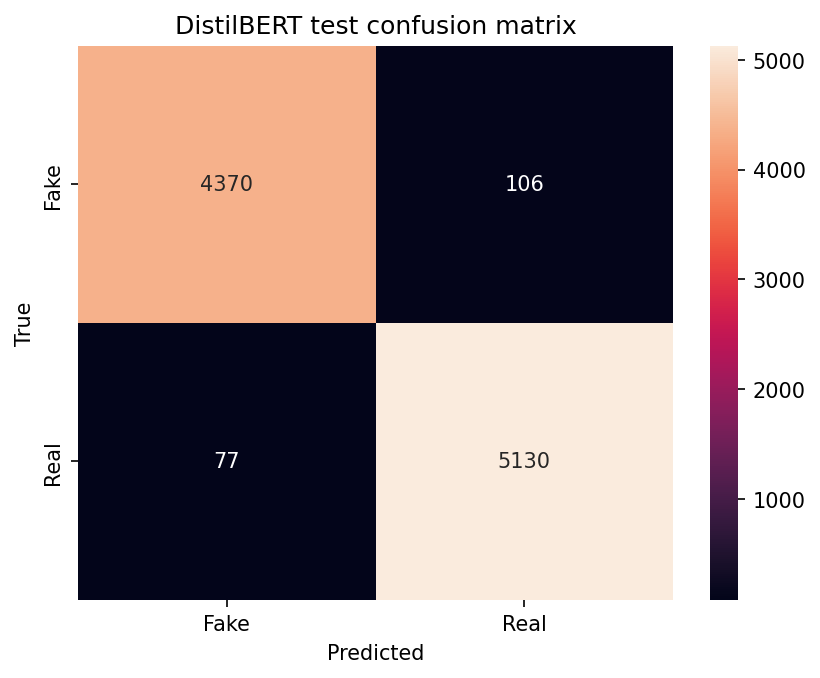

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d', xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'])
plt.title("DistilBERT test confusion matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
save_figure('test_confusion_matrix')
plt.show()

## Test errors

Inspect up to five incorrect headlines. These examples can suggest failure patterns, but do not establish which features caused the predictions.

In [144]:
error_cases_found = 0
max_errors_to_display = 5

for i in range(len(y_pred)):
    if y_pred[i] != y_true[i]:
        if error_cases_found < max_errors_to_display:
            print("\nIncorrect prediction")
            print("Text:", X_test.iloc[i][:300])
            print("True:", y_true[i], "Pred:", y_pred[i])
            error_cases_found += 1
        else:
            break


Incorrect prediction
Text: behind scenes, ivanka encouraged trump’s change of tone: sources
True: 1 Pred: 0

Incorrect prediction
Text: patriots demand removal of communist flag
True: 0 Pred: 1

Incorrect prediction
Text: petty faa rebukes trump
True: 0 Pred: 1

Incorrect prediction
Text: target caves after customers boycott of transgender bathroom policy takes toll bottom line
True: 0 Pred: 1

Incorrect prediction
Text: trump given unverified reports that russia had damaging details about him
True: 1 Pred: 0


## RQ3: custom headline result

Evaluate the same 40 reference headlines used by the classical models. The loader verifies texts and labels so that both notebooks use the same set.

DistilBERT correctly classifies 30 examples, giving 75% accuracy. Headline-only LinearSVC correctly classifies 23, giving 57.5%. The difference is 17.5 percentage points on this selected set.

In [145]:
EXPECTED_CUSTOM_COUNT = 40
with CUSTOM_PATH.open(encoding='utf-8') as handle:
    custom_records = json.load(handle)

if not isinstance(custom_records, list) or len(custom_records) != EXPECTED_CUSTOM_COUNT:
    found = len(custom_records) if isinstance(custom_records, list) else 'a non-list object'
    raise ValueError(
        f'Custom file: {CUSTOM_PATH.resolve()}. Found {found}; expected 40 records. '
        'Copy data/evaluation/custom_headlines.json from the repository to the same '
        'location under PROJECT_ROOT on Drive, then rerun this cell. Training does not need to be repeated.'
    )

expected_ids = {f'{prefix}_{i:02d}' for prefix in ['synthetic', 'reported'] for i in range(1, 21)}
if any(not isinstance(row, dict) or not {'id', 'text', 'label'} <= row.keys() for row in custom_records):
    raise ValueError('Each custom record must contain id, text and label. Copy the original JSON from the repository.')
if {row['id'] for row in custom_records} != expected_ids:
    raise ValueError('Custom record IDs differ from the shared 40-example set. Copy the original JSON from the repository.')
if any(not isinstance(row['text'], str) or not row['text'].strip() or row['label'] not in (0, 1) for row in custom_records):
    raise ValueError('Custom records require non-empty text and binary labels 0/1.')
if sum(row['label'] == 0 for row in custom_records) != 20:
    raise ValueError('The shared custom set must contain 20 Fake and 20 Real labels.')

import hashlib

EXPECTED_CUSTOM_SHA256 = '78afa2aff9c167ddfef84ae64ec4f8cab3febf6a74425d9ac37bd065024a882c'

def custom_fingerprint(records):
    values = [{'id': row['id'], 'text': row['text'], 'label': row['label']}
              for row in sorted(records, key=lambda row: row['id'])]
    payload = json.dumps(values, ensure_ascii=False, sort_keys=True, separators=(',', ':'))
    return hashlib.sha256(payload.encode('utf-8')).hexdigest()

def verify_custom_set(records):
    actual = custom_fingerprint(records)
    if actual != EXPECTED_CUSTOM_SHA256:
        raise ValueError(
            f'The custom headlines or labels in {CUSTOM_PATH.resolve()} differ from the shared benchmark. '
            'Copy the original data/evaluation/custom_headlines.json from the repository. '
            ''
            'Keep the trained model and rerun custom loading and inference.'
        )
    return actual

custom_dataset_sha256 = verify_custom_set(custom_records)

custom_sentences = [row['text'] for row in custom_records]
custom_labels = [row['label'] for row in custom_records]
print(f'Custom file: {CUSTOM_PATH.resolve()}')
print(f'Loaded {len(custom_records)} headlines: 20 Fake and 20 Real.')

print(f'Original benchmark verified: {custom_dataset_sha256[:12]}')

Custom file: /content/data/evaluation/custom_headlines.json
Loaded 40 headlines: 20 Fake and 20 Real.
Original benchmark verified: 78afa2aff9c1


In [146]:
custom_inference_sha256 = verify_custom_set(custom_records)
custom_sentences = [row['text'] for row in custom_records]
custom_labels = [row['label'] for row in custom_records]
if len(custom_records) != 40 or len(custom_sentences) != 40 or len(custom_labels) != 40:
    raise ValueError('Expected the 40 shared headlines. Rerun the custom-file loading cell before inference.')
custom_inputs = [clean_news_text(value).lower() for value in custom_sentences]
model.to(device)
model.eval()
probability_batches = []
for start in range(0, len(custom_inputs), EVAL_BATCH_SIZE):
    encodings = tokenizer(
        custom_inputs[start:start + EVAL_BATCH_SIZE],
        truncation=True, padding='max_length', max_length=256, return_tensors='pt')
    encodings = {key: value.to(device) for key, value in encodings.items()}
    with torch.no_grad():
        logits = model(**encodings).logits
        probability_batches.append(torch.softmax(logits, dim=1).cpu())
custom_probabilities = torch.cat(probability_batches).numpy()
preds = custom_probabilities.argmax(axis=1)
confidence_scores = custom_probabilities.max(axis=1)
if custom_probabilities.shape != (len(custom_records), 2):
    raise RuntimeError(f'Expected 40 binary predictions, got {custom_probabilities.shape}. Rerun custom inference.')
print(f'Evaluated {len(preds)}/{len(custom_records)} custom headlines.')

Evaluated 40/40 custom headlines.


In [147]:
if verify_custom_set(custom_records) != custom_inference_sha256:
    raise ValueError('Custom data changed after inference. Rerun inference before using these predictions.')
if not (len(custom_records) == len(preds) == len(confidence_scores) == 40):
    raise ValueError('Incomplete predictions. Rerun custom-file loading and inference before displaying results.')

prediction_table = pd.DataFrame({
    'id': [row['id'] for row in custom_records],
    'headline': custom_sentences,
    'expected': ['Real' if label == 1 else 'Fake' for label in custom_labels],
    'predicted': ['Real' if label == 1 else 'Fake' for label in preds],
    'score': confidence_scores,
})
print(f'Predictions for all {len(prediction_table)} custom headlines:')
display(prediction_table.style.format({'score': '{:.4f}'}))

Predictions for all 40 custom headlines:


,id,headline,expected,predicted,score
0,synthetic_01,President Donald said on Tuesday that talks with GOP officials were progressing after recent policy discussions,Fake,Fake,0.9989
1,synthetic_02,Hillary Clinton told Reuters on Wednesday that new proposals would be reviewed following recent developments in Congress,Fake,Fake,0.9977
2,synthetic_03,President Barack said on Thursday in a Reuters interview that long-term reforms remain a priority heading into November,Fake,Real,0.8745
3,synthetic_04,White House officials said on Monday that new sanctions against Iran would be delayed pending talks with European allies,Fake,Real,0.9957
4,synthetic_05,Senate Republicans introduced a revised immigration proposal after overnight negotiations with Democratic lawmakers,Fake,Real,0.9794
5,synthetic_06,Federal Reserve officials discussed possible emergency measures following renewed concerns over regional bank stability,Fake,Real,0.9850
6,synthetic_07,U.S. officials told reporters that military advisers would remain in eastern Syria despite earlier withdrawal plans,Fake,Real,0.9969
7,synthetic_08,Supreme Court conservatives appeared divided during arguments over state restrictions on early voting access,Fake,Fake,0.8356
8,synthetic_09,State Department officials confirmed that trade negotiations with China would resume next month in Singapore,Fake,Real,0.9995
9,synthetic_10,Donald Trump told supporters during a rally in Ohio that new tariffs on imported vehicles were under consideration,Fake,Fake,0.9980


In [148]:
if verify_custom_set(custom_records) != custom_inference_sha256:
    raise ValueError('Custom data changed after inference. Rerun inference before using these predictions.')
if not (len(custom_records) == len(custom_labels) == len(preds) == 40):
    raise ValueError('Expected 40 custom predictions. Rerun custom-file loading and inference before computing metrics or comparisons.')

custom_accuracy = accuracy_score(custom_labels, preds)
custom_precision = precision_score(custom_labels, preds)
custom_recall = recall_score(custom_labels, preds)
custom_f1 = f1_score(custom_labels, preds)

print("Classification report")

print(
    classification_report(
        custom_labels,
        preds,
        target_names=["Fake", "Real"]
    )
)

custom_report = classification_report(custom_labels, preds, target_names=['Fake', 'Real'], output_dict=True, zero_division=0)
(METRICS_DIR / 'custom_metrics.json').write_text(json.dumps(custom_report, indent=2) + '\n', encoding='utf-8')
custom_predictions = pd.DataFrame(custom_records)
custom_predictions['prediction'] = preds
custom_predictions['confidence'] = confidence_scores
custom_predictions.to_csv(METRICS_DIR / 'custom_predictions.csv', index=False)

Classification report
              precision    recall  f1-score   support

        Fake       0.81      0.65      0.72        20
        Real       0.71      0.85      0.77        20

    accuracy                           0.75        40
   macro avg       0.76      0.75      0.75        40
weighted avg       0.76      0.75      0.75        40



## Class-level results

DistilBERT identifies 13 of 20 examples assigned Fake and 17 of 20 assigned Real. Fake recall is 65%, Real recall is 85%, and macro F1 is 0.7475.

For the headline-only LinearSVC, Fake recall is 25% and Real recall is 90%. DistilBERT's gain comes mainly from recognizing more examples assigned Fake, with one fewer correct Real prediction.

Accuracy still drops from 98.11% internally to 75% on the custom set. One prediction changes custom accuracy by 2.5 percentage points, so the sample supports a limited comparison rather than a general performance estimate.

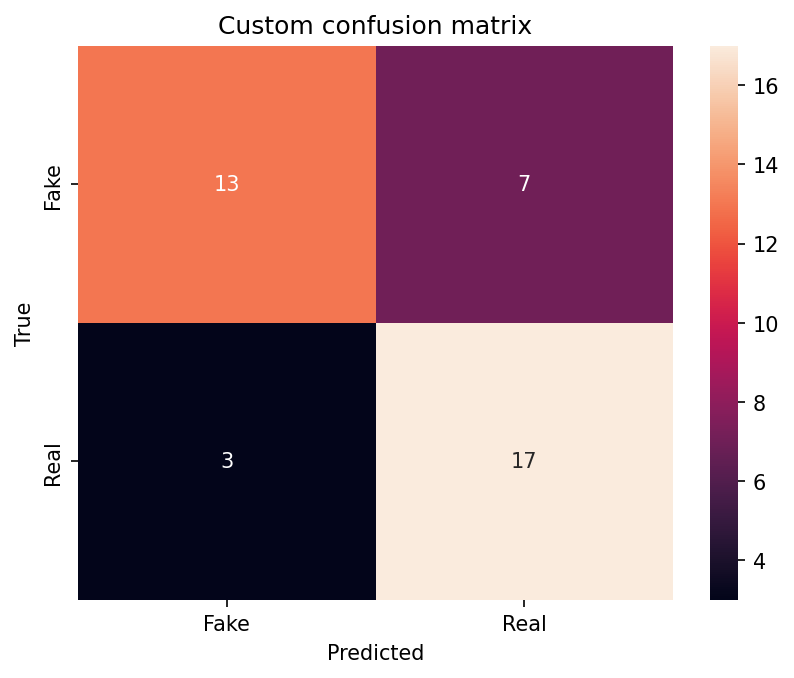

In [ ]:
cm = confusion_matrix(custom_labels, preds)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d', xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'])
plt.title("Custom confusion matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
save_figure('custom_confusion_matrix')
plt.show()

## Remaining errors

Seven synthetic headlines are predicted Real: six concern politics and one claims that solar cooling would reverse global warming. Examples such as the headline about delaying sanctions against Iran use formal reporting language. Their wording resembles news in the training collection, but their synthetic labels are not independently verified factuality judgments.

All 15 Reuters-attributed headlines are predicted Real, compared with 2 of the 5 AP News headlines. The three missed AP examples concern climate or environmental science. With so few examples and different topics, source and topic effects cannot be separated.

Several errors have high softmax scores. This illustrates that confidence in a prediction does not establish its correctness.

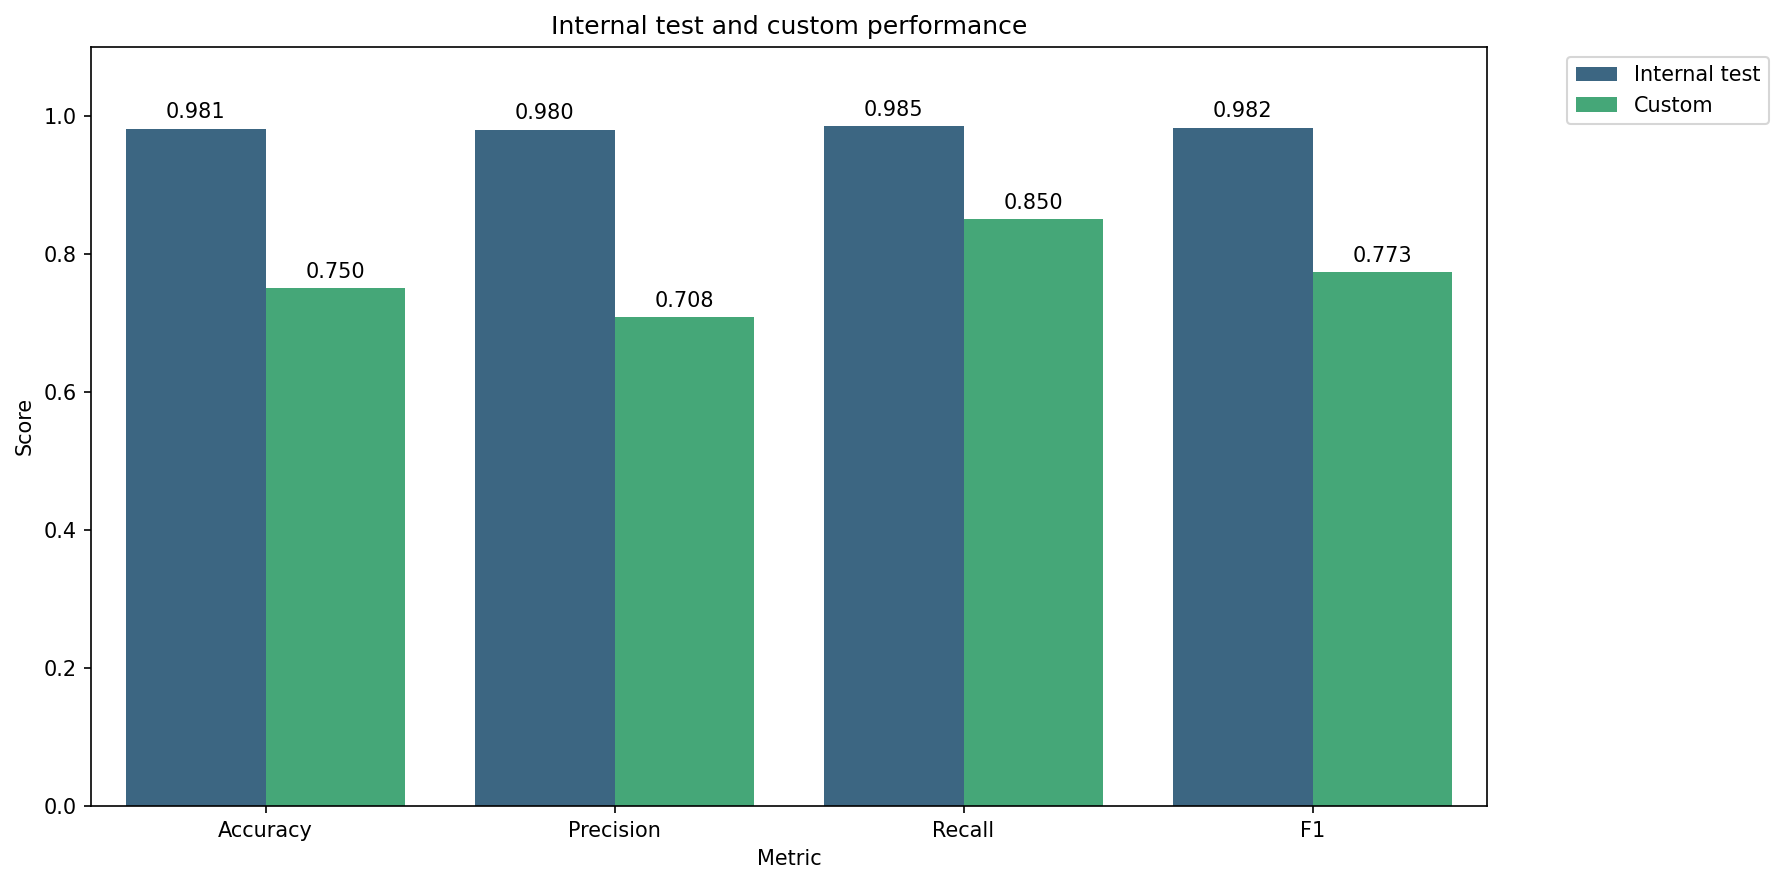

In [ ]:
plot_data = pd.DataFrame({
    'Dataset': ['Internal test'] * 4 + ['Custom'] * 4,
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1'] * 2,
    'Value': [results['test_accuracy'], results['test_precision'],
              results['test_recall'], results['test_f1'],
              custom_accuracy, custom_precision, custom_recall, custom_f1],
})
plt.figure(figsize=(12, 6))
ax = sns.barplot(x='Metric', y='Value', hue='Dataset', data=plot_data, palette='viridis')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3)
plt.ylim(0, 1.1)
plt.title('Internal test and custom performance')
plt.ylabel('Score')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
save_figure('test_custom_comparison')
plt.show()


## Conclusions

**RQ1.** The source and style associations found in notebook 1 remain relevant because DistilBERT learns from the same collection. Its errors on formal synthetic headlines and some AP News examples are compatible with limited transfer, but do not identify a causal shortcut.

**RQ2.** Classical TF-IDF performance falls on the custom set. Full-text models reach 35-45%, while the headline-only baseline reaches 57.5%. The latter still has a large gap from its 91.95% internal score.

**RQ3.** DistilBERT improves custom accuracy from 57.5% to 75%, with seven additional correct predictions. Fake recall improves from 25% to 65%; Real recall changes from 90% to 85%. The result supports better transfer on these 40 examples. It does not isolate the contribution of pretraining, architecture or regularization, and it does not demonstrate fact verification.

The project shows why internal accuracy should be read alongside dataset analysis and evaluation on different examples. A stronger model improves the result here, while the training collection and the evaluation sample still limit the conclusions.

## Future work

- Train on more diverse true and false news, with better coverage of sources, topics, dates and styles in each class.
- Build a larger external set with source links, dates and verified labels, including plausible false claims and real headlines written in different styles.
- Compare pretrained encoders with more parameters using the same partitions and metrics. Report training/inference cost as well as performance; increased capacity may still learn dataset-specific cues.

The summary below combines the exported results when the classical files are available and their partitions match.

In [ ]:
if verify_custom_set(custom_records) != custom_inference_sha256:
    raise ValueError('Custom data changed after inference. Rerun inference before using these predictions.')
if not (len(custom_records) == len(custom_labels) == len(preds) == 40):
    raise ValueError('Expected 40 custom predictions. Rerun custom-file loading and inference before computing metrics or comparisons.')

from IPython.display import Markdown, display

distilbert_test_accuracy = float(results['test_accuracy'])
distilbert_custom_accuracy = float(custom_accuracy)
comparison_rows = [{'model': 'DistilBERT', 'training input': 'headline',
    'test accuracy': distilbert_test_accuracy, 'custom accuracy': distilbert_custom_accuracy}]
classical_dir = PROJECT_ROOT / 'results' / 'metrics' / '01_classical_ml'
needed = ['partitions.csv', 'test_metrics.csv', 'custom_metrics.csv', 'headline_svc_metrics.csv']
can_compare = all((classical_dir / name).is_file() for name in needed)
if can_compare:
    baseline_partitions = pd.read_csv(classical_dir / 'partitions.csv').sort_values('row_id').reset_index(drop=True)
    current_partitions = pd.read_csv(METRICS_DIR / 'partitions.csv').sort_values('row_id').reset_index(drop=True)
    can_compare = baseline_partitions.equals(current_partitions)

if can_compare:
    baseline_test = pd.read_csv(classical_dir / 'test_metrics.csv', index_col=0)
    baseline_custom = pd.read_csv(classical_dir / 'custom_metrics.csv', index_col=0)
    baseline_headline = pd.read_csv(classical_dir / 'headline_svc_metrics.csv').set_index('partition')
    for prefix, name in [('XGB', 'XGBoost'), ('LinearSVC', 'LinearSVC'), ('MLP', 'MLP (Neural Net)')]:
        internal = baseline_test.loc[baseline_test.index.str.startswith(prefix)].iloc[0]
        comparison_rows.append({'model': name, 'training input': 'title + body',
            'test accuracy': internal['Accuracy'], 'custom accuracy': baseline_custom.loc[name, 'Accuracy']})
    reference = float(baseline_headline.loc['custom', 'accuracy'])
    comparison_rows.append({'model': 'LinearSVC headline baseline', 'training input': 'headline',
        'test accuracy': baseline_headline.loc['test', 'accuracy'], 'custom accuracy': reference})
    difference = 100 * (distilbert_custom_accuracy - reference)
    outcome = 'higher than' if difference > 0 else 'lower than' if difference < 0 else 'equal to'
    display(Markdown(
        f'**Answer to RQ3:** DistilBERT reaches {distilbert_custom_accuracy:.1%} custom accuracy, '
        f'{outcome} the headline-only LinearSVC reference ({reference:.1%}). '
        f'The difference is {difference:+.1f} percentage points on 40 examples. '
        'This is a comparison on the selected stress test; its labels require verification.'))
else:
    display(Markdown('**Answer to RQ3:** the DistilBERT result is available, but the baseline files '
        'are missing or their partitions differ. No cross-model conclusion is generated. '
        'Copy the matching classical metrics folder and rerun this cell.'))

comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(METRICS_DIR / 'model_comparison.csv', index=False)
display(comparison.style.format({'test accuracy': '{:.2%}', 'custom accuracy': '{:.2%}'}))

**Answer to RQ3:** DistilBERT reaches 75.0% custom accuracy, higher than the headline-only LinearSVC reference (57.5%). The difference is +17.5 percentage points on 40 examples. This is a comparison on the selected stress test; its labels require verification.

,model,training input,test accuracy,custom accuracy
0,DistilBERT,headline,98.11%,75.00%
1,XGBoost,title + body,97.88%,35.00%
2,LinearSVC,title + body,97.98%,45.00%
3,MLP (Neural Net),title + body,97.75%,35.00%
4,LinearSVC headline baseline,headline,91.95%,57.50%
